# Grouping Chess games based on game information
## Question
Is it possible to group Chess games based on different game statistics, like move count, player ratings, opening moves played, etc. This notebook attempts to group games using the kmeans clustering algorithm.

The target is to plot the clusters and visually see distinct groups.


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler



In [12]:
data = pd.read_csv('../Resources/games_data.csv', index_col=0)
data.head(1)

,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
id,,,,,,,,,,,,,,,
TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5


## Selecting our features
First we have to select our baseline features we'd like to group. We will begin with just both player ratings, opening plies, and the turn count.

In [13]:
features = ['white_rating', 'black_rating', 'opening_ply', 'turns']

X = data[features].dropna()
print(X.head())

          white_rating  black_rating  opening_ply  turns
id                                                      
TZJHLljE          1500          1191            5     13
l1NXvwaE          1322          1261            4     16
mIICvQHh          1496          1500            3     61
kWKvrqYL          1439          1454            3     61
9tXo1AUZ          1523          1469            5     95


In [14]:
def number_of_checks(moves):
    moves = moves.split()
    return sum(1 for move in moves if '+' in move)

def number_of_captures(moves, colour):
    moves = moves.split()
    if (colour == 'white'):
        return sum(1 for i, move in enumerate(moves) if 'x' in move and i % 2 == 0)
    return sum(1 for i, move in enumerate(moves) if 'x' in move and i % 2 == 1)

def number_of_castles(moves):
    moves = moves.split()
    return sum(1 for move in moves if 'O-O' in move or 'O-O-O' in move)



## Additional features
The basic features might not have enough variation to produce any clear groups. Since we have the move list for each game, we can quite easily calculate a lot of information about the game itself, e.g. number of captures, number of checks.

In [15]:
X['number_of_checks'] = data['moves'].apply(number_of_checks)
X['number_of_captures_white'] = data['moves'].apply(number_of_captures, colour='white')
X['number_of_captures_black'] = data['moves'].apply(number_of_captures, colour='black')
X['number_of_castles'] = data['moves'].apply(number_of_castles)

Some features, however, might skew the cluster values, so we can transform the features using a scaler.

In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Training the model
Now that the data is ready, we can create our clustering model and train it. 

In [17]:
CLUSTER_COUNT = 4
kmeans = KMeans(n_clusters=CLUSTER_COUNT, random_state=42)

clusters = kmeans.fit_predict(X_scaled)
X['cluster'] = clusters

Lets see the results of the clustering and see the summery of the clusters.

In [18]:
cluster_summary = X.groupby("cluster")[X.columns].mean()
print(cluster_summary)

         white_rating  black_rating  opening_ply       turns  \
cluster                                                        
0         1605.967342   1610.825030     4.664839  108.763528   
1         1876.573293   1867.017023     6.552109   56.175903   
2         1474.756249   1454.212568     3.912402   23.283028   
3         1438.637647   1432.363137     4.074196   56.745098   

         number_of_checks  number_of_captures_white  number_of_captures_black  \
cluster                                                                         
0               11.296544                 12.133969                 12.057449   
1                2.888595                  6.684698                  6.700965   
2                1.503452                  2.636039                  2.544632   
3                4.137098                  7.391529                  7.336157   

         number_of_castles  cluster  
cluster                              
0                 1.542074      0.0  
1             

## Cluster Insights
Lets analyse these groups and attempt to make an association for each of them.

### Cluster 0 - Long Games, average rating
- Cluster 0 consists of the longest games at 108 turns on average. The average rating is around 1600 and spans the whole range of ratings. The average number of captures is around 12, and the average number of checks is around 11. This cluster seems to represent games that are longer and more strategic.
- Longer games tend to have more captures and especially checks in endgames, which is consistent with the data we see here.
- We can call this cluster "Long Strategic Games".

### Cluster 1 - Medium length games, high rating
- Cluster 1 consists of the highest rated players, with an average rating of 1800+. The average game here has about 50 turns, 6 of which are openings, which would indicate that these players are more experienced and know how to play the opening well. The average number of captures is around 6, and the average number of checks is around 3. 
- This group also has the highest number of castles (even more than the long games cluster) which is consistent with the idea that these players are more experienced and know how to play the opening well.
- We can call this cluster "Highly Rated Tactical Games".

### Cluster 2 - Short games, average rating
- Cluster 2 consists of the shortest games, with an average of 23 turns. The average rating is around 1400, and the average number of captures is around 3, with an average of 1 check. This group has the lowest number of castles among all the clusters. This cluster seems to represent games that are shorter where the game didn't transform into an endgame.
- Shorter games tend to have fewer captures and checks, which is consistent with the data we see here.
- This group could also contain games in which one player made a mistake early on, leading to a quick loss.
- We can call this cluster "Short Tactical Games".

### Cluster 3 - Medium length games, low - average rating
- Cluster 3 consists of games with an average of 50 turns and an average rating of around 1400. The average number of captures is around 7, and the average number of checks is around 4. This cluster seems to represent games that are more balanced in terms of length and strategy.
- This group has the lowest elo range, which would indicate that these players are between the beginner and intermediate level. The average number of castles is around 1.4, which is consistent with the idea that these players are still learning how to play the opening well.
- This group also has less opening moves played, which is consistent with the idea that these players are still learning how to play the opening well.
- An interesting observation is that this group has the a higher number of checks and captures than the highly rated tactical games cluster. This could indicate that less experienced players are more likely to make mistakes that lead to checks and captures, or that they are more likely to make snap captures and checks without fully considering the consequences. This could also indicate that these players are more likely to play aggressively, which could lead to more captures and checks.
- We can call this cluster "Intermediate Strategic Games".

Lets plot our clusters and see how they look visually.

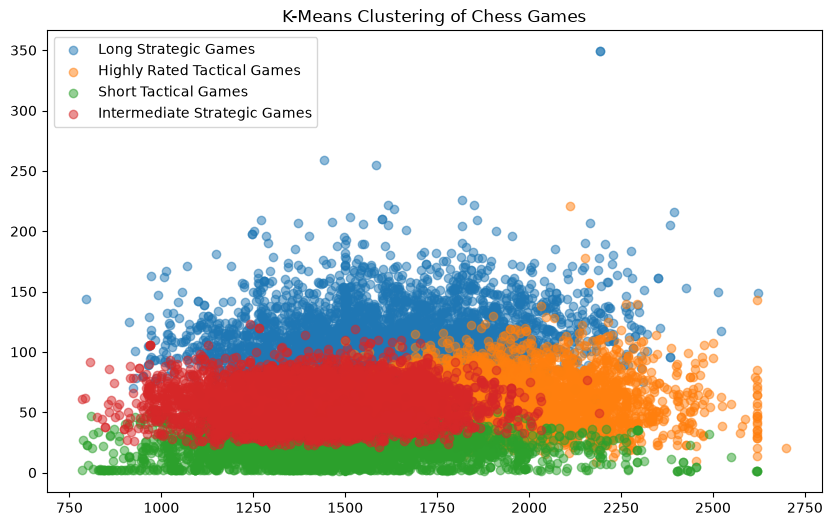

In [19]:
cluster_labels = {
    0: "Long Strategic Games",
    1: "Highly Rated Tactical Games",
    2: "Short Tactical Games",
    3: "Intermediate Strategic Games"
}

# Plot the clusters in a loop
plt.figure(figsize=(10, 6))
for cluster in range(CLUSTER_COUNT):
    cluster_data = X[X['cluster'] == cluster]
    plt.scatter(cluster_data['white_rating'], cluster_data['turns'], label=f'{cluster_labels[cluster]}', alpha=0.5)
plt.title('K-Means Clustering of Chess Games')
plt.legend()
plt.show()